# Fase 2b · Sentinel-2: NDVI y NDBI de la ZMG, noviembre 2020 contra noviembre 2026 (issue #21)

Factor **cambio de uso de suelo y densificación urbana** del `PLAN.md`. Se comparan dos imágenes multiespectrales de Sentinel-2 (nivel L2A, reflectancia de superficie) tomadas casi el mismo día del año:

| Año | Fecha | Satélite | Nubes |
|---|---|---|---|
| 2020 | 3 de noviembre | Sentinel-2A | 0.0 % |
| 2026 | 2 de noviembre | Sentinel-2C | 0.1–2.9 % |

**¿Por qué noviembre?** Al terminar la temporada de lluvias casi no hay nubes y la vegetación sigue verde. En temporada seca el suelo desnudo refleja mucho en el infrarrojo de onda corta y el NDBI lo confunde con construcción; en lluvias casi siempre hay nubes. Usar el mismo mes en ambos años evita que el cambio de NDVI se deba a la temporada y no a la urbanización.

| Paso | Operación |
|---|---|
| 1 | Rejilla del proyecto (la misma de la Fase 2a) y búsqueda de escenas en el catálogo STAC de Element 84 |
| 2 | Lectura de las bandas B04 (rojo), B08 (infrarrojo cercano), B11 (infrarrojo de onda corta) y SCL, y mosaico de las 4 cuadrículas |
| 3 | Máscara de nubes, sombras y agua con la banda SCL |
| 4 | Cálculo de **NDVI** y **NDBI** pixel a pixel |
| 5 | Cambio 2020 → 2026 (ΔNDVI y ΔNDBI) |
| 6 | Guardado de los rásters |

**Entradas:** `data/processed/rasters/dem_elevation.tif` (solo para copiar la rejilla), `data/imeplan/LimiteAMG/LimiteAMG.shp` y las escenas públicas de Sentinel-2 (se leen por internet, sin cuenta de AWS).
**Salidas:** `data/processed/rasters/ndvi_2020.tif`, `ndvi_2026.tif`, `delta_ndvi_2020_2026.tif`, `ndbi_2020.tif`, `ndbi_2026.tif`, `delta_ndbi_2020_2026.tif` y las figuras en `outputs/figuras/`.

Esta etapa no depende de la base de socavones: los socavones se cruzan con estos rásters hasta la Fase 3 (malla de 250 m).

**1.** Cargar las librerías, copiar la rejilla de la Fase 2a (`EPSG:32613`, 20 m) para que los pixeles queden alineados con la pendiente y el TPI, y buscar las escenas de Sentinel-2 que cubren la ZMG:

In [1]:
# Código del Paso 1
#Importación de Librerías
import os
from pathlib import Path
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from pystac_client import Client
import matplotlib.pyplot as plt

#Lectura de archivos públicos por internet sin cuenta de AWS
os.environ["AWS_NO_SIGN_REQUEST"] = "YES"
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"

#Rutas de Entrada y Salida
RAIZ = Path("..")
RASTERS = RAIZ / "data/processed/rasters"
LIMITE = RAIZ / "data/imeplan/LimiteAMG/LimiteAMG.shp"
FIG = RAIZ / "outputs/figuras"
FIG.mkdir(parents=True, exist_ok=True)
FUENTE = "Fuente: elaboración propia con imágenes Sentinel-2 L2A (ESA/Copernicus, vía Element 84) y el límite del AMG (IMEPLAN)."

#Rejilla del proyecto: la misma de la Fase 2a
with rasterio.open(RASTERS / "dem_elevation.tif") as ref:
    CRS, T, alto, ancho = ref.crs, ref.transform, ref.height, ref.width
extension = [T.c / 1000, (T.c + T.a * ancho) / 1000, (T.f + T.e * alto) / 1000, T.f / 1000]   # en km
print("Rejilla:", CRS, "| pixel de %d m | dimensiones %d x %d" % (T.a, alto, ancho))

#Máscara de la ZMG
limite = gpd.read_file(LIMITE).to_crs(CRS)
dentro = ~geometry_mask(limite.geometry, out_shape=(alto, ancho), transform=T)

#Búsqueda de escenas (catálogo STAC público de Element 84)
catalogo = Client.open("https://earth-search.aws.element84.com/v1")
caja = list(limite.to_crs(4326).total_bounds)
FECHAS = {2020: "2020-11-03", 2026: "2026-11-02"}
escenas = {}
for anio, fecha in FECHAS.items():
    items = catalogo.search(collections=["sentinel-2-l2a"], bbox=caja, datetime=fecha).items()
    #En 2020 hay dos versiones de cada escena; se usa la reprocesada (baseline >= 05.00) para que sea comparable con 2026
    escenas[anio] = [i for i in items if float(i.properties["s2:processing_baseline"]) >= 5]
    for i in escenas[anio]:
        print(anio, i.id, "| nubes %.1f %%" % i.properties["eo:cloud_cover"], "| baseline", i.properties["s2:processing_baseline"])

Rejilla: EPSG:32613 | pixel de 20 m | dimensiones 3969 x 4409


2020 S2A_13QFC_20201103_1_L2A | nubes 0.0 % | baseline 05.00
2020 S2A_13QGC_20201103_1_L2A | nubes 0.0 % | baseline 05.00
2020 S2A_13QFD_20201103_1_L2A | nubes 0.0 % | baseline 05.00
2020 S2A_13QGD_20201103_1_L2A | nubes 0.0 % | baseline 05.00


2026 S2C_13QFC_20261102_0_L2A | nubes 2.9 % | baseline 05.13
2026 S2C_13QGC_20261102_0_L2A | nubes 1.2 % | baseline 05.13
2026 S2C_13QFD_20261102_0_L2A | nubes 0.6 % | baseline 05.13
2026 S2C_13QGD_20261102_0_L2A | nubes 0.1 % | baseline 05.13


**2.** Leer las bandas de cada escena directamente sobre la rejilla del proyecto. `WarpedVRT` lee solo la parte de la imagen que cae en la ZMG y la lleva a pixeles de 20 m: las bandas de 10 m (B04 y B08) se promedian y la SCL (clases) se toma con vecino más cercano. Como la ZMG cae en 4 cuadrículas de Sentinel-2, se hace un **mosaico**: cada pixel toma el valor de la primera cuadrícula que tenga dato.

Los valores se guardan como enteros (DN). Desde 2022 la ESA suma 1,000 a los DN (offset de −0.1 en reflectancia), pero el catálogo de Element 84 **ya lo restó** en ambas fechas (propiedad `earthsearch:boa_offset_applied = True`, que se verifica abajo). Por eso la **reflectancia** es solo:

$$\rho = DN \cdot 0.0001$$

In [2]:
# Código del Paso 2
def leer_banda(escenas, banda, metodo):
    #Mosaico de una banda de varias escenas sobre la rejilla del proyecto
    mosaico = np.zeros((alto, ancho), dtype=np.float64)
    for item in escenas:
        with rasterio.open(item.assets[banda].href) as src:
            with WarpedVRT(src, crs=CRS, transform=T, width=ancho, height=alto,
                           resampling=metodo, nodata=0) as vrt:
                datos = vrt.read(1).astype(np.float64)
        #Solo se llenan los pixeles que siguen vacíos (0 = sin dato)
        vacio = mosaico == 0
        mosaico[vacio] = datos[vacio]
    return mosaico

def reflectancia(dn):
    #Conversión de número digital a reflectancia de superficie (NaN donde no hay dato)
    return np.where(dn > 0, dn * 0.0001, np.nan)

#Verificación: el offset de +1000 ya viene restado en todas las escenas
for anio in FECHAS:
    assert all(i.properties.get("earthsearch:boa_offset_applied") for i in escenas[anio])
print("Offset de reflectancia ya aplicado en todas las escenas: True")

bandas = {}
for anio in FECHAS:
    bandas[anio] = {
        "rojo": reflectancia(leer_banda(escenas[anio], "red", Resampling.average)),
        "nir": reflectancia(leer_banda(escenas[anio], "nir", Resampling.average)),
        "swir": reflectancia(leer_banda(escenas[anio], "swir16", Resampling.bilinear)),
        "scl": leer_banda(escenas[anio], "scl", Resampling.nearest).astype(np.uint8),
    }
    cubierto = np.isfinite(bandas[anio]["rojo"]) & dentro
    print("%d: dimensiones %s | ZMG cubierta: %.1f %%" % (anio, bandas[anio]["rojo"].shape, 100 * cubierto.sum() / dentro.sum()))

Offset de reflectancia ya aplicado en todas las escenas: True


2020: dimensiones (3969, 4409) | ZMG cubierta: 100.0 %


2026: dimensiones (3969, 4409) | ZMG cubierta: 100.0 %


**3.** Construir la **máscara de pixeles válidos** con la banda SCL (*Scene Classification Layer*), que clasifica cada pixel. Se descartan:

| Clase SCL | Significado |
|---|---|
| 0, 1 | Sin dato, pixel saturado |
| 3 | Sombra de nube |
| 6 | Agua (el NDBI no tiene sentido sobre agua) |
| 8, 9, 10 | Nube media, nube alta, cirros |

Un pixel se usa solo si es válido **en ambos años**, para que el cambio no se calcule contra una nube:

In [3]:
# Código del Paso 3
CLASES_NO_VALIDAS = [0, 1, 3, 6, 8, 9, 10]

def mascara_valida(scl):
    return ~np.isin(scl, CLASES_NO_VALIDAS)

valido = dentro.copy()
for anio in FECHAS:
    v = mascara_valida(bandas[anio]["scl"])
    print("%d: pixeles no válidos dentro de la ZMG: %.2f %%" % (anio, 100 * (dentro & ~v).sum() / dentro.sum()))
    valido &= v
print("Pixeles válidos en ambos años: %.2f %% de la ZMG" % (100 * valido.sum() / dentro.sum()))

2020: pixeles no válidos dentro de la ZMG: 0.59 %
2026: pixeles no válidos dentro de la ZMG: 1.62 %
Pixeles válidos en ambos años: 98.35 % de la ZMG


**4.** Calcular los índices **pixel a pixel** con operaciones de matrices de NumPy:

$$NDVI=\frac{NIR-Rojo}{NIR+Rojo}\qquad\qquad NDBI=\frac{SWIR-NIR}{SWIR+NIR}$$

* **NDVI** (índice de vegetación): cerca de +1 en vegetación densa, cerca de 0 en suelo o construcción.
* **NDBI** (índice de construcción): positivo en techos, pavimento y suelo desnudo, negativo en vegetación.

Ambos van de −1 a +1. Al ser cocientes, no dependen de la iluminación de cada fecha, lo que permite comparar los dos años.

2020: NDVI mediana 0.469 | NDBI mediana 0.006


2026: NDVI mediana 0.550 | NDBI mediana -0.030


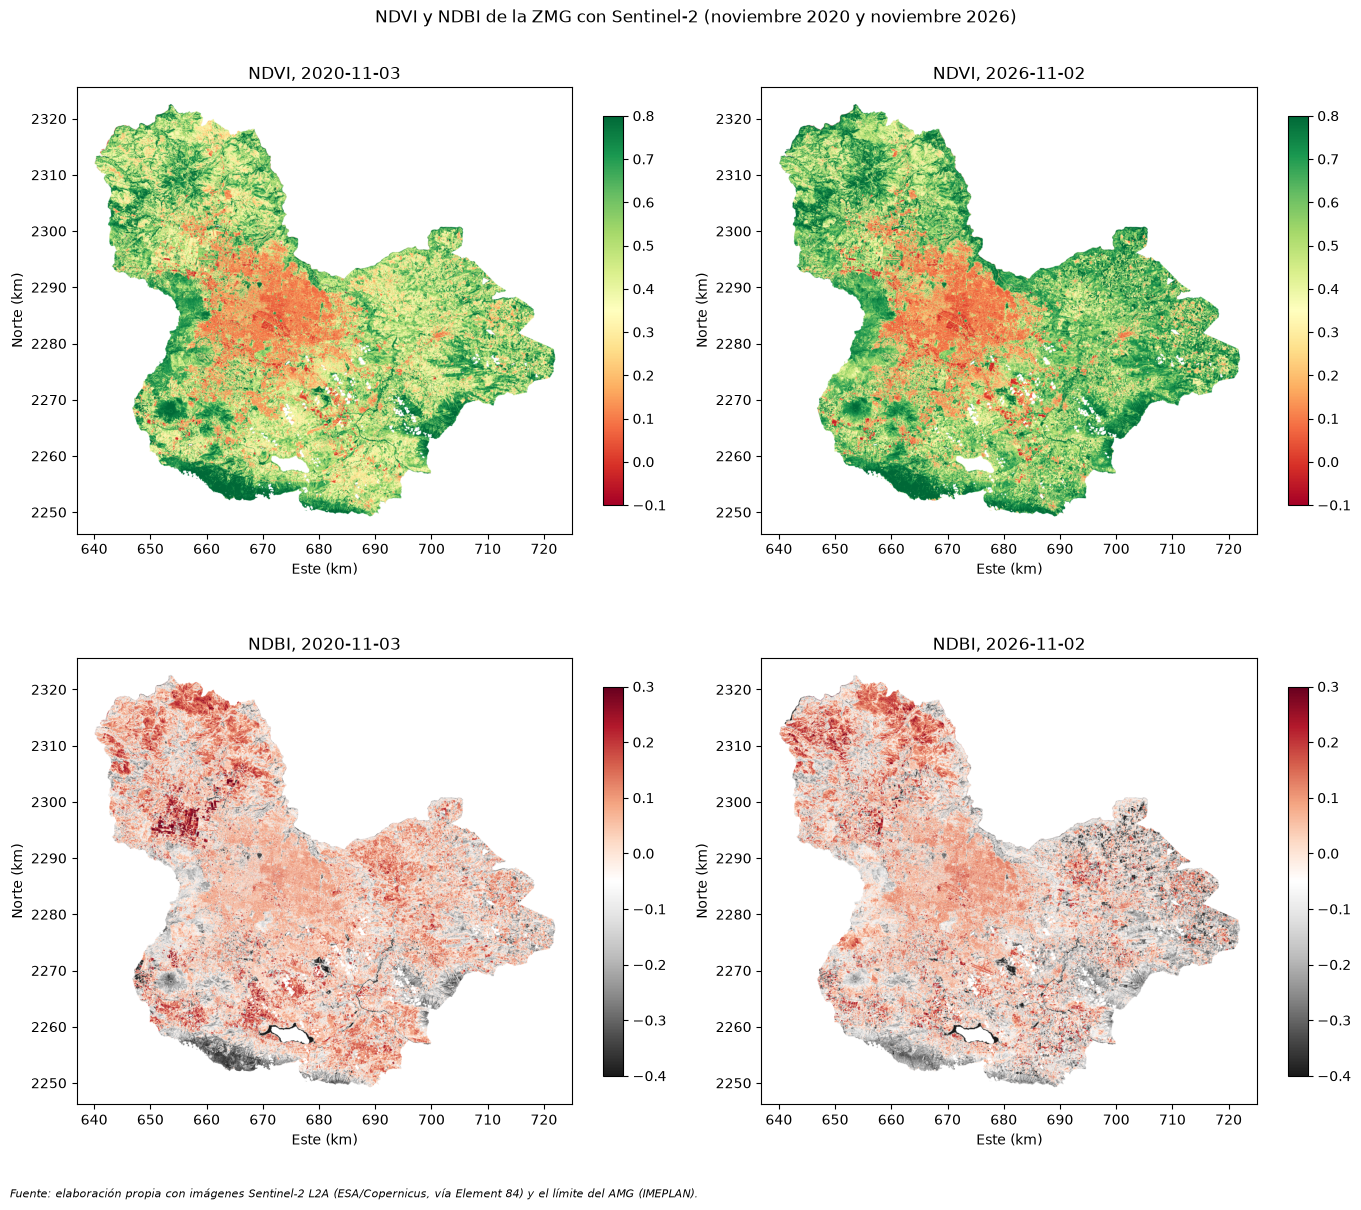

In [4]:
# Código del Paso 4
def indice_normalizado(a, b):
    #(a - b) / (a + b); NaN donde el denominador es 0 o el pixel no es válido
    with np.errstate(divide="ignore", invalid="ignore"):
        resultado = (a - b) / (a + b)
    resultado[~valido] = np.nan
    return np.clip(resultado, -1, 1)

ndvi, ndbi = {}, {}
for anio in FECHAS:
    ndvi[anio] = indice_normalizado(bandas[anio]["nir"], bandas[anio]["rojo"])
    ndbi[anio] = indice_normalizado(bandas[anio]["swir"], bandas[anio]["nir"])
    print("%d: NDVI mediana %.3f | NDBI mediana %.3f" % (anio, np.nanmedian(ndvi[anio]), np.nanmedian(ndbi[anio])))

fig, ax = plt.subplots(2, 2, figsize=(14, 12))
for j, anio in enumerate(FECHAS):
    im = ax[0, j].imshow(ndvi[anio], cmap="RdYlGn", vmin=-0.1, vmax=0.8, extent=extension)
    ax[0, j].set_title("NDVI, %s" % FECHAS[anio])
    plt.colorbar(im, ax=ax[0, j], shrink=0.7)
    im = ax[1, j].imshow(ndbi[anio], cmap="RdGy_r", vmin=-0.4, vmax=0.3, extent=extension)
    ax[1, j].set_title("NDBI, %s" % FECHAS[anio])
    plt.colorbar(im, ax=ax[1, j], shrink=0.7)
for a in ax.ravel():
    a.set_xlabel("Este (km)")
    a.set_ylabel("Norte (km)")
plt.suptitle("NDVI y NDBI de la ZMG con Sentinel-2 (noviembre 2020 y noviembre 2026)")
plt.tight_layout()
plt.figtext(0.01, -0.01, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "fase2b_paso4_ndvi_ndbi.png", dpi=200, bbox_inches="tight")
plt.show()

**5.** Calcular el **cambio** entre los dos años restando las imágenes pixel a pixel:

$$\Delta NDVI = NDVI_{2026} - NDVI_{2020}\qquad\qquad \Delta NDBI = NDBI_{2026} - NDBI_{2020}$$

Un ΔNDVI negativo indica **pérdida de vegetación** y un ΔNDBI positivo, **más superficie construida o suelo descubierto**. Los umbrales de cambio fuerte (ΔNDVI < −0.2 y ΔNDBI > 0.1) se usan solo para describir; en la Fase 3 entran los valores continuos.

ΔNDVI: mediana +0.035 | percentil 5 -0.178 | percentil 95 +0.284


ΔNDBI: mediana -0.012 | percentil 5 -0.246 | percentil 95 +0.135
Pérdida fuerte de vegetación (ΔNDVI < -0.2): 4.2 % de la ZMG (135 km²)
Aumento fuerte de NDBI (ΔNDBI > 0.1): 8.7 % de la ZMG (279 km²)


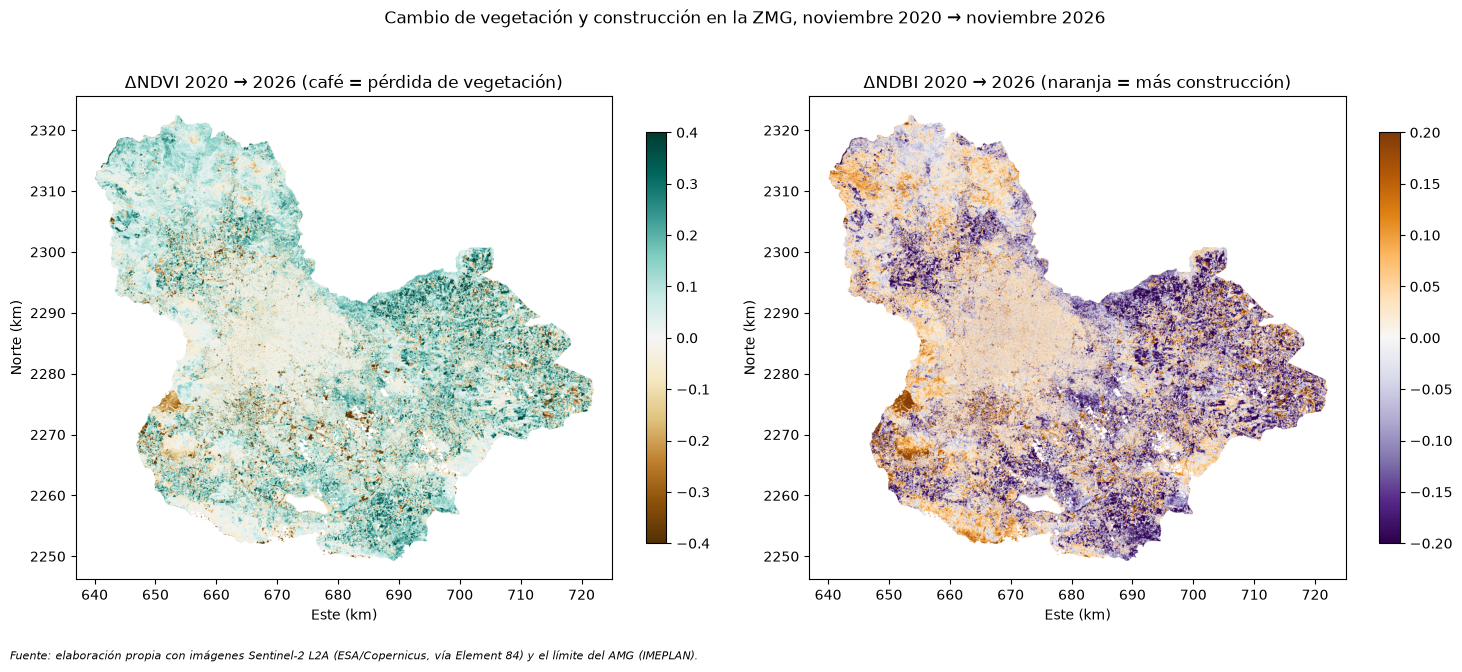

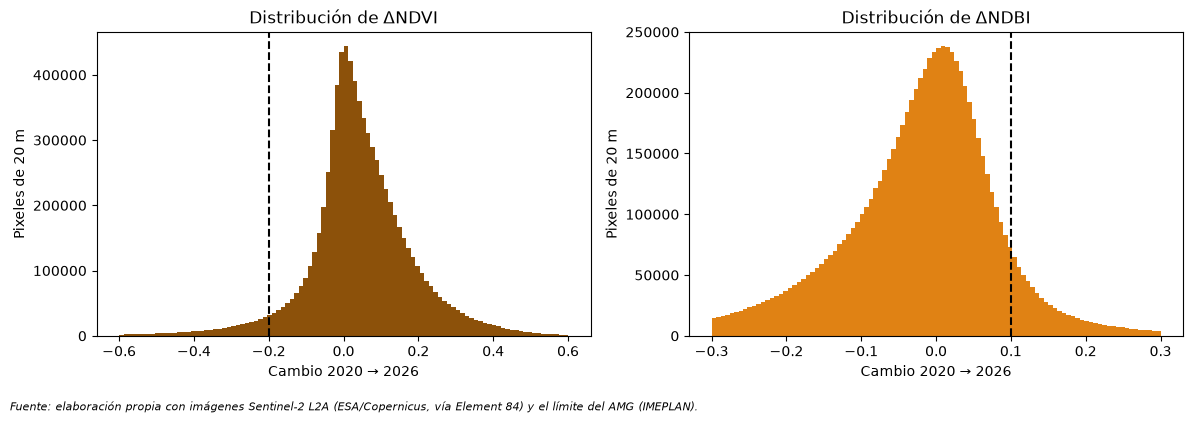

In [5]:
# Código del Paso 5
delta_ndvi = ndvi[2026] - ndvi[2020]
delta_ndbi = ndbi[2026] - ndbi[2020]

print("ΔNDVI: mediana %+.3f | percentil 5 %+.3f | percentil 95 %+.3f" % tuple(np.nanpercentile(delta_ndvi, [50, 5, 95])))
print("ΔNDBI: mediana %+.3f | percentil 5 %+.3f | percentil 95 %+.3f" % tuple(np.nanpercentile(delta_ndbi, [50, 5, 95])))
area = np.isfinite(delta_ndvi).sum()
perdida = np.nansum(delta_ndvi < -0.2)
construido = np.nansum(delta_ndbi > 0.1)
print("Pérdida fuerte de vegetación (ΔNDVI < -0.2): %.1f %% de la ZMG (%.0f km²)" % (100 * perdida / area, perdida * 400 / 1e6))
print("Aumento fuerte de NDBI (ΔNDBI > 0.1): %.1f %% de la ZMG (%.0f km²)" % (100 * construido / area, construido * 400 / 1e6))

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
im = ax[0].imshow(delta_ndvi, cmap="BrBG", vmin=-0.4, vmax=0.4, extent=extension)
ax[0].set_title("ΔNDVI 2020 → 2026 (café = pérdida de vegetación)")
plt.colorbar(im, ax=ax[0], shrink=0.7)
im = ax[1].imshow(delta_ndbi, cmap="PuOr_r", vmin=-0.2, vmax=0.2, extent=extension)
ax[1].set_title("ΔNDBI 2020 → 2026 (naranja = más construcción)")
plt.colorbar(im, ax=ax[1], shrink=0.7)
for a in ax:
    a.set_xlabel("Este (km)")
    a.set_ylabel("Norte (km)")
plt.suptitle("Cambio de vegetación y construcción en la ZMG, noviembre 2020 → noviembre 2026")
plt.tight_layout()
plt.figtext(0.01, -0.02, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "fase2b_paso5_cambio.png", dpi=200, bbox_inches="tight")
plt.show()

#Histogramas del cambio
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(delta_ndvi[np.isfinite(delta_ndvi)], bins=100, range=(-0.6, 0.6), color="#8c510a")
ax[0].axvline(-0.2, color="black", linestyle="--")
ax[0].set_title("Distribución de ΔNDVI")
ax[1].hist(delta_ndbi[np.isfinite(delta_ndbi)], bins=100, range=(-0.3, 0.3), color="#e08214")
ax[1].axvline(0.1, color="black", linestyle="--")
ax[1].set_title("Distribución de ΔNDBI")
for a in ax:
    a.set_xlabel("Cambio 2020 → 2026")
    a.set_ylabel("Pixeles de 20 m")
plt.tight_layout()
plt.figtext(0.01, -0.04, FUENTE, fontsize=8, style="italic")
plt.savefig(FIG / "fase2b_paso5_histogramas.png", dpi=200, bbox_inches="tight")
plt.show()

**6.** Guardar los seis rásters como GeoTIFF en la rejilla del proyecto (fuera de la ZMG o en pixeles no válidos = sin dato):

In [6]:
# Código del Paso 6
SIN_DATO = -9999.0

def guardar_raster(arreglo, nombre):
    salida = np.where(np.isfinite(arreglo) & dentro, arreglo, SIN_DATO).astype(np.float32)
    perfil = dict(driver="GTiff", height=alto, width=ancho, count=1, dtype="float32",
                  crs=CRS, transform=T, nodata=SIN_DATO, compress="deflate", tiled=True)
    with rasterio.open(RASTERS / nombre, "w", **perfil) as dst:
        dst.write(salida, 1)
    print("Guardado: %-26s %.1f MB" % (nombre, (RASTERS / nombre).stat().st_size / 1e6))

for anio in FECHAS:
    guardar_raster(ndvi[anio], "ndvi_%d.tif" % anio)
    guardar_raster(ndbi[anio], "ndbi_%d.tif" % anio)
guardar_raster(delta_ndvi, "delta_ndvi_2020_2026.tif")
guardar_raster(delta_ndbi, "delta_ndbi_2020_2026.tif")

Guardado: ndvi_2020.tif              28.5 MB


Guardado: ndbi_2020.tif              29.7 MB


Guardado: ndvi_2026.tif              28.3 MB


Guardado: ndbi_2026.tif              29.6 MB


Guardado: delta_ndvi_2020_2026.tif   29.9 MB


Guardado: delta_ndbi_2020_2026.tif   29.9 MB


#### Limitaciones:
* Se compara una sola fecha por año: un noviembre más húmedo o más seco que el otro puede mover el NDVI aunque la ciudad no cambie.
* Las escenas son de satélites distintos (Sentinel-2A en 2020 y Sentinel-2C en 2026); sus sensores están calibrados para ser equivalentes, pero puede haber diferencias pequeñas de reflectancia.
* El NDBI también sube con el suelo desnudo (terrenos desmontados, cultivos levantados), no solo con construcción; por eso se interpreta junto con el ΔNDVI.
* La resolución de 20 m capta fraccionamientos y vialidades nuevas, pero no la densificación dentro de una manzana ya construida.